# A hypoxia-independent FLT1 program? Discovery in GSE114691 → validation in GSE203507 (Addendum F)

Addendum F (module definition and predictions V1–V3) was committed before this notebook was run.
**Discovery uses only GSE114691; the module is frozen before GSE203507 is touched.**
Run notebooks 01 and 05 first (downloads).

In [1]:
import os, sys, warnings
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); EXT = ROOT / "data_external"
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(EXT / "h.all.v2024.1.Hs.symbols.gmt")}
HYP = set(gmt["HALLMARK_HYPOXIA"])
N_MODULE = 50

def vst_of(counts, groups):
    counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
    md = pd.DataFrame({"g": groups}, index=counts.columns)
    dds = DeseqDataSet(counts=counts.T.astype(int), metadata=md, design="~g", inference=DefaultInference(n_cpus=4), quiet=True)
    dds.fit_size_factors(); dds.vst(use_design=False)
    return pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)

def zscore(v):
    return (v - v.mean()) / v.std()

def hyp_score(vst):
    z = zscore(vst); return z[sorted(g for g in HYP if g in z.columns)].mean(axis=1)

def partial_spearman(x, y, covs):
    """Spearman partial correlation: Pearson of rank residuals after regressing on ranked covariates."""
    R = np.column_stack([np.ones(len(x))] + [stats.rankdata(c) for c in covs])
    rx = stats.rankdata(x); ry = stats.rankdata(y)
    ex = rx - R @ np.linalg.lstsq(R, rx, rcond=None)[0]; ey = ry - R @ np.linalg.lstsq(R, ry, rcond=None)[0]
    r = np.corrcoef(ex, ey)[0, 1]; df = len(x) - 2 - len(covs)
    t = r * np.sqrt(df / (1 - r ** 2)); return r, stats.t.sf(t, df)  # one-sided p (r > 0)

## F1. Discovery in GSE114691

In [2]:
tx2gene = pd.read_csv(EXT / "grch37_tx2gene.tsv", sep="\t").set_index("Transcript stable ID")["Gene name"]
parts = []
for g, f in {"control": "ControlONLY", "IUGR": "IUGRONLY", "PE": "PEONLY", "PE+IUGR": "PEIUGR"}.items():
    d = pd.read_csv(EXT / f"GSE114691_MasterCount_{f}.txt.gz", sep="\t", index_col=0); d.columns = [f"{g}|{c}" for c in d.columns]; parts.append(d)
tx = pd.concat(parts, axis=1); m = tx.index.isin(tx2gene.index)
gc_r = tx[m].groupby(tx2gene.reindex(tx.index[m]).values).sum().round().astype(int)
grp_r = pd.Series([c.split("|")[0] for c in gc_r.columns], index=gc_r.columns)
vst_r = vst_of(gc_r, grp_r.str.startswith("PE").values)
h_r = hyp_score(vst_r)

# residualise every gene on the hypoxia score (rank-based), then correlate with the FLT1 residual
ranks = vst_r.rank(axis=0)
H = np.column_stack([np.ones(len(h_r)), stats.rankdata(h_r)])
beta = np.linalg.lstsq(H, ranks.values, rcond=None)[0]
res = ranks.values - H @ beta
res = pd.DataFrame(res, index=vst_r.index, columns=vst_r.columns)
f_res = res["FLT1"]
rc = res.sub(res.mean()); fc = f_res - f_res.mean()
pcor = (rc.mul(fc, axis=0).sum()) / np.sqrt((rc ** 2).sum() * (fc ** 2).sum())
pcor = pcor.drop(index="FLT1").dropna()
cand = pcor[~pcor.index.isin(HYP)].sort_values(ascending=False)
module = list(cand.index[:N_MODULE])
pd.DataFrame({"gene": module, "partial_rho_GSE114691": cand.iloc[:N_MODULE].values}).to_csv(RES_DIR / "F1_module_genes.csv", index=False)
print(f"Module frozen ({N_MODULE} genes). Partial rho range: {cand.iloc[N_MODULE-1]:.2f} to {cand.iloc[0]:.2f}")
print(", ".join(module))
known = ["LEP", "ENG", "INHA", "PAPPA2", "HTRA4", "PGF"]
print("Known PE genes in module:", [g for g in known if g in module], "| their partial rho:", {g: round(pcor.get(g, np.nan), 2) for g in known})

universe = set(vst_r.columns)
rows = []
for name, genes in gmt.items():
    gs = set(genes) & universe; k = len(gs & set(module))
    rows.append({"set": name, "overlap": k, "set_size": len(gs),
                 "p": stats.hypergeom.sf(k - 1, len(universe), len(gs), len(module)) if k > 0 else 1.0})
enr = pd.DataFrame(rows); enr["q_BH"] = multipletests(enr.p, method="fdr_bh")[1]
enr = enr.sort_values("p"); enr.to_csv(RES_DIR / "F1_module_hallmark_enrichment.csv", index=False)
print(enr.head(8).round(4).to_string(index=False))

Module frozen (50 genes). Partial rho range: 0.77 to 0.94
ZYG11A, PAPPA2, LEP, GBA, SPAG4, ENG, GBAP1, INHBA, RP11-228B15.4, SIPA1L1, RP11-631F7.1, SH3PXD2A, HTRA4, LIMCH1, PPP1R1C, FLT1P1, FSTL3, PROCR, EBI3, OR10Y1P, SASH1, SLC6A8, RP11-141M3.5, MYO7B, PIK3AP1, HTRA1, OCRL, CCDC183, ADAM12, INHBA-AS1, C10orf90, RP11-216L13.19, FOXJ3, CSNK2A2, ARMS2, GUCA2A, MTX1, SSFA2, CCDC113, PRRG1, ERGIC1, PVRL4, TBC1D26, TMEM59, PNCK, BCL6, TET3, SREBF1, COG3, CYP11A1
Known PE genes in module: ['LEP', 'ENG', 'PAPPA2', 'HTRA4'] | their partial rho: {'LEP': np.float64(0.89), 'ENG': np.float64(0.87), 'INHA': np.float64(0.84), 'PAPPA2': np.float64(0.89), 'HTRA4': np.float64(0.84), 'PGF': np.float64(0.34)}
                                       set  overlap  set_size      p   q_BH
HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION        5       190 0.0000 0.0010
                       HALLMARK_MYOGENESIS        2       176 0.0381 0.3817
                HALLMARK_KRAS_SIGNALING_UP        2       183 0.0409 0.

## F2. Validation in GSE203507 (independent patients)

In [3]:
counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
vst_d = vst_of(counts, meta.pe_status.values)
z_d = zscore(vst_d)
mod_d = [g for g in module if g in z_d.columns]
print(f"Module genes measured in GSE203507: {len(mod_d)}/{N_MODULE}")
d = meta[["group", "ga_delivery_weeks", "fetal_sex"]].copy()
d["module"] = z_d[mod_d].mean(axis=1); d["hyp"] = hyp_score(vst_d); d["FLT1"] = vst_d["FLT1"]
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
stb_genes = [g for g in markers.loc[markers.cell_class == "syncytiotrophoblast", "gene_symbol"] if g in z_d.columns]
d["stb"] = z_d[stb_genes].mean(axis=1)
pre = d[d.group != "TB"].copy()

r1, p1 = partial_spearman(pre.module.values, pre.FLT1.values, [pre.hyp.values])
r1s, p1s = partial_spearman(pre.module.values, pre.FLT1.values, [pre.hyp.values, pre.stb.values])
pre["grp"] = pre.group.map({"iPTB": "ctrl", "EOPE": "EOPE", "EOPE+FGR": "EOPEFGR", "FGR": "FGR"})
f2 = smf.ols("module ~ C(grp, Treatment('ctrl')) + hyp + ga_delivery_weeks + C(fetal_sex)", data=pre).fit()
nm = {g: f"C(grp, Treatment('ctrl'))[T.{g}]" for g in ["EOPE", "EOPEFGR", "FGR"]}
L = np.zeros(len(f2.params)); L[list(f2.params.index).index(nm["EOPE"])] = .5; L[list(f2.params.index).index(nm["EOPEFGR"])] = .5; L[list(f2.params.index).index(nm["FGR"])] = -1
t2 = f2.t_test(L); e2 = float(t2.effect[0]); p2 = float(t2.pvalue) / 2 if e2 > 0 else 1 - float(t2.pvalue) / 2
L2 = np.zeros(len(f2.params)); L2[list(f2.params.index).index(nm["EOPE"])] = 1
t2b = f2.t_test(L2)

# V3: random 50-gene sets matched by expression decile (genes outside the hypoxia set and FLT1)
rng = np.random.default_rng(42)
bins = pd.qcut(vst_d.mean(), 10, labels=False)
eligible = bins.index[~bins.index.isin(HYP) & (bins.index != "FLT1") & ~bins.index.isin(mod_d)]
need = bins.loc[sorted(mod_d)].value_counts().sort_index()
pool = {b: np.array(sorted(set(eligible) & set(bins.index[bins == b]))) for b in range(10)}
null = []
for _ in range(1000):
    pick = np.concatenate([rng.choice(pool[b], n, replace=False) for b, n in need.items()])
    null.append(partial_spearman(z_d.loc[pre.index, pick].mean(axis=1).values, pre.FLT1.values, [pre.hyp.values])[0])
null = np.array(null); p3 = (1 + (null >= r1).sum()) / 1001

val = pd.DataFrame([
    {"prediction": "V1 partial rho(module, FLT1 | hypoxia) > 0, 25 preterm", "estimate": r1, "p_one_sided": p1, "pass": p1 < 0.05},
    {"prediction": "V2 module: PE (both) - FGR-only > 0 | hypoxia, GA, sex", "estimate": e2, "p_one_sided": p2, "pass": p2 < 0.05},
    {"prediction": "V3 V1 beats 1,000 matched random 50-gene sets", "estimate": float(np.quantile(null, 0.95)), "p_one_sided": p3, "pass": p3 < 0.05},
    {"prediction": "(robustness) V1 also adjusting for STB marker score", "estimate": r1s, "p_one_sided": p1s, "pass": p1s < 0.05},
    {"prediction": "(descriptive) module: EOPE - preterm control | hypoxia, GA, sex", "estimate": float(t2b.effect[0]),
     "p_one_sided": float(t2b.pvalue) / 2 if t2b.effect[0] > 0 else 1 - float(t2b.pvalue) / 2, "pass": np.nan},
])
val.to_csv(RES_DIR / "F2_validation.csv", index=False)
print(val.round(4).to_string(index=False))
print("Claim supported (V1 and V3 pass):", bool(val["pass"].iloc[0] and val["pass"].iloc[2]))

Module genes measured in GSE203507: 44/50


                                                     prediction  estimate  p_one_sided pass
         V1 partial rho(module, FLT1 | hypoxia) > 0, 25 preterm    0.8869       0.0000 True
         V2 module: PE (both) - FGR-only > 0 | hypoxia, GA, sex    0.5857       0.0238 True
                  V3 V1 beats 1,000 matched random 50-gene sets    0.4910       0.0010 True
            (robustness) V1 also adjusting for STB marker score    0.8742       0.0000 True
(descriptive) module: EOPE - preterm control | hypoxia, GA, sex    0.7153       0.0238  NaN
Claim supported (V1 and V3 pass): True


## F3. Where are the module genes expressed? (single-cell pseudobulk, descriptive)

In [4]:
pb = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv", index_col=0)
pbm = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv", index_col=0)
keep = pbm.index[pbm.n_cells >= 20]
cpm = pb[keep] / pb[keep].sum() * 1e6
prof = pd.DataFrame({k: cpm[pbm.loc[keep].index[pbm.loc[keep, "cell_class"] == k]].mean(axis=1) for k in sorted(pbm.cell_class.unique())})
mod_pb = [g for g in module if g in prof.index]
top_class = prof.loc[mod_pb].idxmax(axis=1)
loc = top_class.value_counts().rename("n_module_genes_highest_in_class").to_frame()
loc["fraction"] = loc.iloc[:, 0] / len(mod_pb); loc.to_csv(RES_DIR / "F3_module_location.csv"); print(loc.round(2))
print("\nFLT1 highest in:", prof.loc["FLT1"].idxmax())

mdp = pbm[(pbm.cell_class == "syncytiotrophoblast") & (pbm.clinical_group == "PE_early")]
c = pb[mdp.index]; c = c.loc[(c >= 10).sum(axis=1) >= 3]; lc = np.log2(c / c.sum() * 1e6 + 1)
zz = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
ms = zz.loc[zz.index.intersection(mod_pb)].mean(); hs = zz.loc[zz.index.intersection(sorted(HYP))].mean()
r3, p3c = partial_spearman(ms.values, lc.loc["FLT1"].values, [hs.values])
print(f"Early-PE syncytiotrophoblast (n={len(mdp)}): partial rho(module, FLT1 | hypoxia) = {r3:.2f}, one-sided p = {p3c:.3f}")
pd.DataFrame([{"set": "early-PE STB pseudobulk", "n": len(mdp), "partial_rho": r3, "p_one_sided": p3c}]).to_csv(RES_DIR / "F3_stb_partial.csv", index=False)

                          n_module_genes_highest_in_class  fraction
extravillous_trophoblast                               25      0.56
syncytiotrophoblast                                     8      0.18
endothelial_cell                                        4      0.09
hofbauer_cell                                           3      0.07
villous_cytotrophoblast                                 2      0.04
monocyte                                                2      0.04
stromal_cell                                            1      0.02

FLT1 highest in: extravillous_trophoblast
Early-PE syncytiotrophoblast (n=10): partial rho(module, FLT1 | hypoxia) = 0.33, one-sided p = 0.196


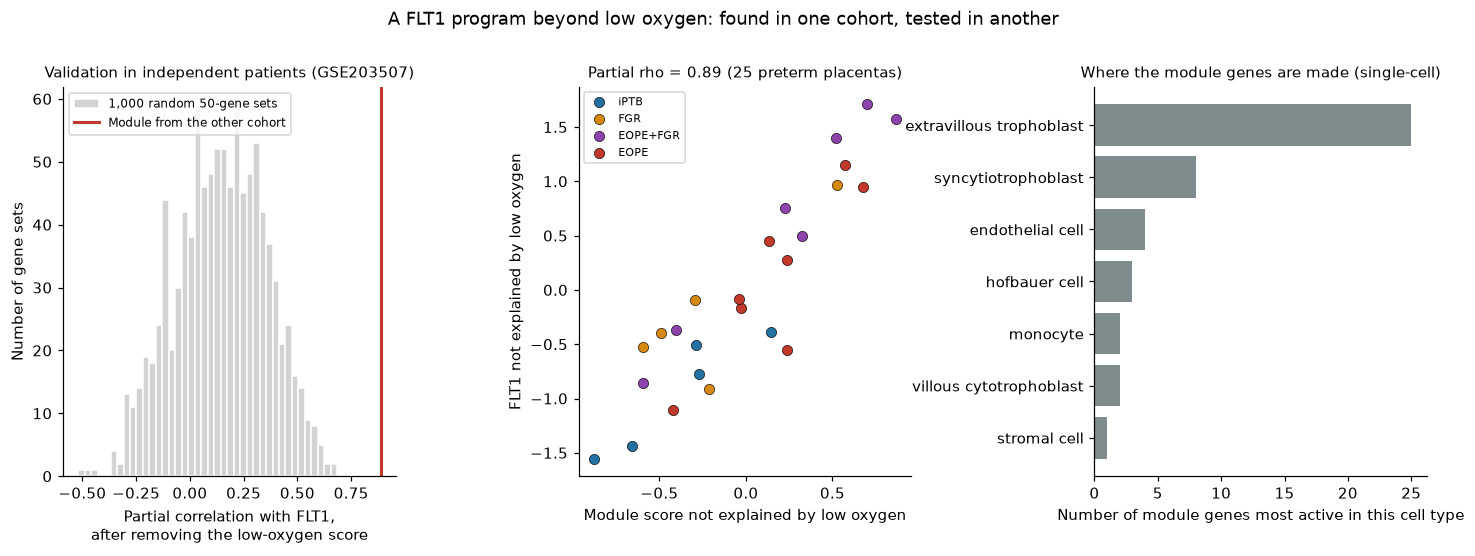

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"wspace": 0.55})
ax = axes[0]
ax.hist(null, bins=40, color="lightgrey", edgecolor="white", label="1,000 random 50-gene sets")
ax.axvline(r1, c="#c0392b", lw=2, label="Module from the other cohort")
ax.set_xlabel("Partial correlation with FLT1,\nafter removing the low-oxygen score"); ax.set_ylabel("Number of gene sets")
ax.set_title("Validation in independent patients (GSE203507)", fontsize=10); ax.legend(fontsize=8)
ax = axes[1]
col = {"iPTB": "#2471a3", "FGR": "#d68910", "EOPE+FGR": "#8e44ad", "EOPE": "#c0392b"}
rx = pre.module - np.polyval(np.polyfit(pre.hyp, pre.module, 1), pre.hyp)
ry = pre.FLT1 - np.polyval(np.polyfit(pre.hyp, pre.FLT1, 1), pre.hyp)
for g, cc in col.items():
    mm = pre.group == g; ax.scatter(rx[mm], ry[mm], c=cc, s=45, edgecolor="k", lw=0.4, label=g)
ax.set_xlabel("Module score not explained by low oxygen"); ax.set_ylabel("FLT1 not explained by low oxygen")
ax.set_title(f"Partial rho = {r1:.2f} (25 preterm placentas)", fontsize=10); ax.legend(fontsize=7)
ax = axes[2]
loc_plot = loc.iloc[:, 0].sort_values()
ax.barh([i.replace("_", " ") for i in loc_plot.index], loc_plot.values, color="#7f8c8d")
ax.set_xlabel("Number of module genes most active in this cell type"); ax.set_title("Where the module genes are made (single-cell)", fontsize=10)
fig.suptitle("A FLT1 program beyond low oxygen: found in one cohort, tested in another", y=1.03)
plt.savefig(FIG_DIR / "fig12_hypoxia_independent_flt1_program.png", dpi=300, bbox_inches="tight"); plt.show()

### F4. Post hoc checks (added after seeing F1–F3; not part of the pre-specified test)
(a) drop pseudogenes / antisense / unannotated transcripts (FLT1P1 may share reads with FLT1);
(b) add an extravillous-trophoblast marker score as covariate (most module genes peak in EVT);
(c) within PE placentas only (removes group differences).

In [6]:
import re
NON_CODING = {"FLT1P1", "GBAP1", "INHBA-AS1", "OR10Y1P"}  # pseudogenes / antisense in the module
clean = [g for g in mod_d if g not in NON_CODING and not g.startswith("RP11-")]
dropped = sorted(set(mod_d) - set(clean)); print("Dropped from module in (a):", dropped)
evt_genes = [g for g in markers.loc[markers.cell_class == "extravillous_trophoblast", "gene_symbol"] if g in z_d.columns]
print("EVT markers used:", evt_genes, "| module genes among EVT markers:", [g for g in evt_genes if g in module])
d["module_clean"] = z_d[clean].mean(axis=1); d["evt"] = z_d[evt_genes].mean(axis=1)
pre = pre.join(d[["module_clean", "evt"]])
pe_only = pre[pre.group.isin(["EOPE", "EOPE+FGR"])]
rows = []
for lab, mod, sub, covs in [
    ("(a) clean module | hypoxia, 25 preterm", "module_clean", pre, ["hyp"]),
    ("(b) module | hypoxia + EVT markers, 25 preterm", "module", pre, ["hyp", "evt"]),
    ("(a+b) clean module | hypoxia + EVT + STB, 25 preterm", "module_clean", pre, ["hyp", "evt", "stb"]),
    ("(c) module | hypoxia, PE only (n=15)", "module", pe_only, ["hyp"]),
    ("(c) clean module | hypoxia + EVT, PE only (n=15)", "module_clean", pe_only, ["hyp", "evt"])]:
    r, p = partial_spearman(sub[mod].values, sub.FLT1.values, [sub[c].values for c in covs])
    rows.append({"check": lab, "n": len(sub), "partial_rho": r, "p_one_sided": p})
f4 = pd.DataFrame(rows); f4.to_csv(RES_DIR / "F4_posthoc_checks.csv", index=False); print(f4.round(4).to_string(index=False))
r_e, p_e = stats.spearmanr(pre.module, pre.evt); print(f"Spearman(module, EVT marker score), 25 preterm: rho = {r_e:.2f}, p = {p_e:.2g}")

Dropped from module in (a): ['GBAP1', 'INHBA-AS1']
EVT markers used: ['HLA-G', 'ITGA1', 'MMP2', 'CEACAM1'] | module genes among EVT markers: []
                                               check  n  partial_rho  p_one_sided
              (a) clean module | hypoxia, 25 preterm 25       0.8745          0.0
      (b) module | hypoxia + EVT markers, 25 preterm 25       0.8380          0.0
(a+b) clean module | hypoxia + EVT + STB, 25 preterm 25       0.8195          0.0
                (c) module | hypoxia, PE only (n=15) 15       0.9286          0.0
    (c) clean module | hypoxia + EVT, PE only (n=15) 15       0.9065          0.0
Spearman(module, EVT marker score), 25 preterm: rho = -0.22, p = 0.28
